In [ ]:
!unzip -q dataset.zip

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

CARGANDO DATASET
Found 82 files belonging to 3 classes.

[INFO] Clases detectadas:
Clase 0: corrosion
Clase 1: fisura
Clase 2: sano

[INFO] Número total de clases: 3

INFORMACIÓN DEL DATASET
Total de imágenes: 82

DIVISIÓN DEL DATASET
Entrenamiento: 57 imágenes (69.5%)
Validación:    16 imágenes (19.5%)
Prueba:        9 imágenes (11.0%)

CONFIGURACIÓN DEL MODELO
Arquitectura: MobileNetV2
Número de clases: 3
Función de costo: sparse_categorical_crossentropy
Métrica principal: Accuracy
Optimizador: Adam
Learning Rate Fase 1: 0.001

FASE 1: ENTRENAMIENTO DEL CABEZAL CLASIFICADOR
Epoch 1/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 12s 441ms/step - accuracy: 0.3684 - loss: 1.3241 - val_accuracy: 0.5000 - val_loss: 1.1094
Epoch 2/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 199ms/step - accuracy: 0.5789 - loss: 1.0775 - val_accuracy: 0.5625 - val_loss: 0.8908
Epoch 3/25
8/8 ━━━━━━━━━━━━━━━━━━━

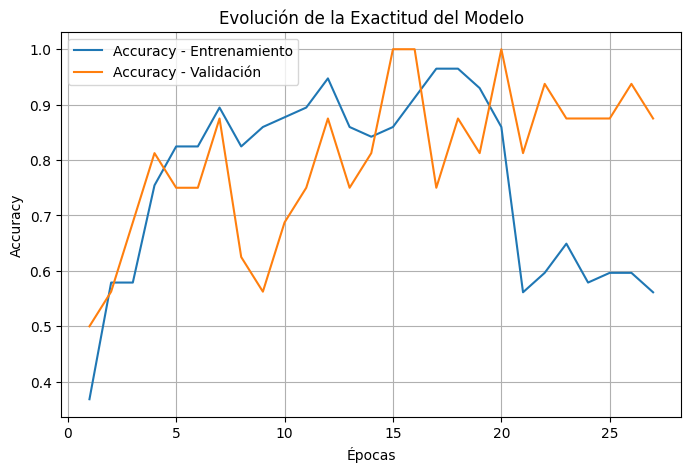

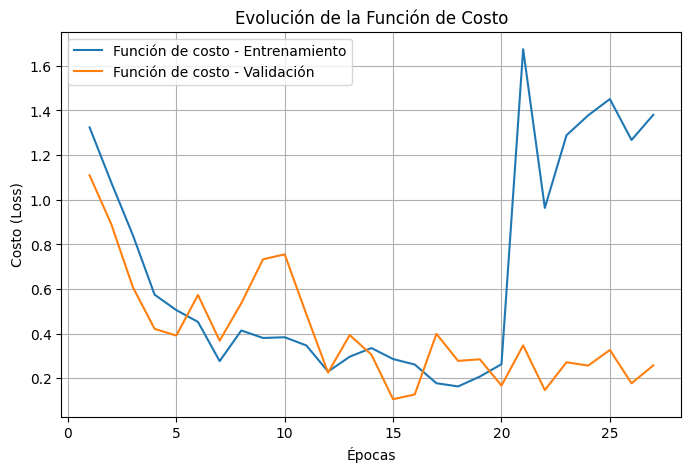


EVALUACIÓN FINAL CON EL CONJUNTO DE PRUEBA
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.8889 - loss: 0.2662

RESULTADOS FINALES DEL TEST:
Función de costo (Test Loss): 0.2662
Accuracy de prueba: 88.89%

REPORTE DE MÉTRICAS DEL MODELO
              precision    recall  f1-score   support

   corrosion     1.0000    0.8000    0.8889         5
      fisura     1.0000    1.0000    1.0000         2
        sano     0.6667    1.0000    0.8000         2

    accuracy                         0.8889         9
   macro avg     0.8889    0.9333    0.8963         9
weighted avg     0.9259    0.8889    0.8938         9



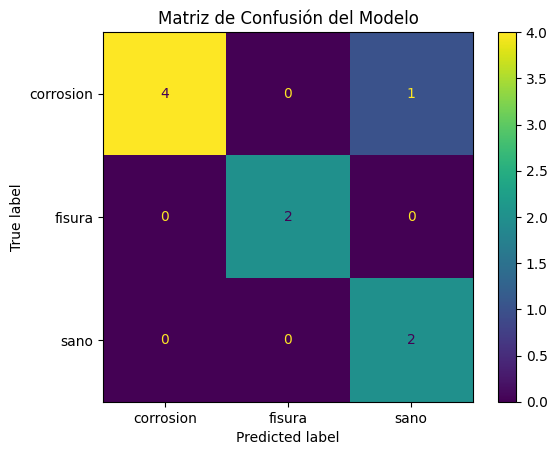


MODELO KERAS GUARDADO
/content/drive/MyDrive/EntrenamientoIA/modelo_shm_multiclase.keras
Saved artifact at '/tmp/tmpbh09lttu'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor_320')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  137398693460496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137398693458576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137398693458384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137398018407120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137398693461840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137398693459344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137398693460688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137398693461072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137398693460112: TensorSpec(shape=(), dtype=tf.resource, nam

In [2]:
# ============================================================
# ENTRENAMIENTO DE MODELO DE INTELIGENCIA ARTIFICIAL PARA SHM
# CLASIFICACIÓN MULTICLASE:
# CORROSIÓN - FISURA - ESTRUCTURA SANA
#
# ARQUITECTURA:
# MobileNetV2 + Transfer Learning + Fine-Tuning
#
# DIVISIÓN DEL DATASET:
# 70% Entrenamiento
# 20% Validación
# 10% Prueba
#
# MÉTRICAS Y EVALUACIÓN:
# - Accuracy (Exactitud)
# - Función de costo (Loss)
# - Precision
# - Recall
# - F1-Score
# - Matriz de confusión
# ============================================================


# ============================================================
# 1. IMPORTACIÓN DE LIBRERÍAS
# ============================================================

import os
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 2. MONTAR GOOGLE DRIVE
# ============================================================

drive.mount('/content/drive')

# ============================================================
# 3. CONFIGURACIÓN GENERAL E HIPERPARÁMETROS
# ============================================================

# Ruta donde se encuentra el dataset organizado por clases
DATASET_PATH = '/content/drive/MyDrive/EntrenamientoIA/imagenes_corrosion_fisura_sano'

# ------------------------------------------------------------
# HIPERPARÁMETROS DEL MODELO
# ------------------------------------------------------------
# Tamaño de entrada de las imágenes
IMG_SIZE = (128, 128)
# Número de imágenes procesadas simultáneamente
BATCH_SIZE = 8
# Semilla para obtener resultados reproducibles
SEED = 123
# Número máximo de épocas durante la primera fase
EPOCHS_FASE_1 = 25
# Número máximo de épocas durante Fine-Tuning
EPOCHS_FASE_2 = 15
# Tasa de aprendizaje inicial
LEARNING_RATE_FASE_1 = 1e-3
# Tasa de aprendizaje para Fine-Tuning
LEARNING_RATE_FASE_2 = 1e-5
# Porcentaje de Dropout
DROPOUT_RATE = 0.3
# Número de épocas de espera para Early Stopping
PATIENCE = 5
# Factor de reducción de MobileNetV2
MOBILENET_ALPHA = 0.35
# Optimización automática de carga de datos
AUTOTUNE = tf.data.AUTOTUNE
# ============================================================
# 4. CARGAR EL DATASET COMPLETO
# ============================================================

print("\n================================================")
print("CARGANDO DATASET")
print("================================================")

# Se carga inicialmente una imagen por elemento para permitir
# una división exacta en entrenamiento, validación y prueba.

full_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    image_size=IMG_SIZE,
    batch_size=None,
    label_mode='int',
    shuffle=True,
    seed=SEED
)
# Obtener nombres de las clases detectadas automáticamente
class_names = full_ds.class_names
NUM_CLASSES = len(class_names)
print("\n[INFO] Clases detectadas:")
for i, clase in enumerate(class_names):
    print(f"Clase {i}: {clase}")
print(f"\n[INFO] Número total de clases: {NUM_CLASSES}")
# ============================================================
# 5. CONTAR EL NÚMERO TOTAL DE IMÁGENES
# ============================================================
total_images = tf.data.experimental.cardinality(full_ds).numpy()
print("\n================================================")
print("INFORMACIÓN DEL DATASET")
print("================================================")
print(f"Total de imágenes: {total_images}")
# ============================================================
# 6. DIVISIÓN DEL DATASET: 70 / 20 / 10
# ============================================================
# 70% para entrenamiento
train_size = int(total_images * 0.70)
# 20% para validación
val_size = int(total_images * 0.20)
# 10% restante para prueba independiente
test_size = total_images - train_size - val_size
# ------------------------------------------------------------
# CREACIÓN DE LOS TRES CONJUNTOS
# ------------------------------------------------------------
# CONJUNTO DE ENTRENAMIENTO (70%)
train_ds = full_ds.take(train_size)
# Datos restantes después del entrenamiento
remaining_ds = full_ds.skip(train_size)
# CONJUNTO DE VALIDACIÓN (20%)
val_ds = remaining_ds.take(val_size)
# CONJUNTO DE PRUEBA (10%)
test_ds = remaining_ds.skip(val_size)
# Mostrar resultados de la división
print("\n================================================")
print("DIVISIÓN DEL DATASET")
print("================================================")
print(
    f"Entrenamiento: {train_size} imágenes "
    f"({train_size / total_images * 100:.1f}%)"
)
print(
    f"Validación:    {val_size} imágenes "
    f"({val_size / total_images * 100:.1f}%)"
)
print(
    f"Prueba:        {test_size} imágenes "
    f"({test_size / total_images * 100:.1f}%)"
)
print("================================================")
# ============================================================
# 7. CREAR LOTES (BATCHES) Y OPTIMIZAR CARGA DE DATOS
# ============================================================
# El entrenamiento utiliza mezcla aleatoria para mejorar
# la generalización del modelo.
train_ds = (
    train_ds
    .shuffle(
        buffer_size=train_size,
        seed=SEED
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
# Validación
val_ds = (
    val_ds
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
# Prueba
test_ds = (
    test_ds
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
# ============================================================
# 8. AUMENTO ARTIFICIAL DE DATOS
# ============================================================
# El Data Augmentation genera variaciones artificiales de las
# imágenes de entrenamiento para mejorar la capacidad de
# generalización del modelo.
data_augmentation = tf.keras.Sequential([

    # Inversión horizontal y vertical
    layers.RandomFlip(
        "horizontal_and_vertical"
    ),
    # Rotación aleatoria
    layers.RandomRotation(
        0.3
    ),
    # Zoom aleatorio
    layers.RandomZoom(
        0.2
    ),
    # Variación de contraste
    layers.RandomContrast(
        0.2
    )
], name="Data_Augmentation")
# ============================================================
# 9. CONFIGURACIÓN DE MOBILENETV2
# ============================================================
# MobileNetV2 se utiliza como extractor de características.
# Se emplean pesos previamente entrenados con ImageNet
# (Transfer Learning).
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights='imagenet',
    alpha=MOBILENET_ALPHA
)
# ------------------------------------------------------------
# FASE 1:
# CONGELAR LAS CAPAS DE MOBILENETV2
# ------------------------------------------------------------
# Durante la primera fase no se modifican los pesos previamente
# aprendidos por MobileNetV2.
base_model.trainable = False
# ============================================================
# 10. CONSTRUCCIÓN DEL MODELO DE CLASIFICACIÓN
# ============================================================
model = models.Sequential([
    # --------------------------------------------------------
    # CAPA DE ENTRADA
    # --------------------------------------------------------
    layers.Input(
        shape=IMG_SIZE + (3,)
    ),
    # --------------------------------------------------------
    # AUMENTO DE DATOS
    # --------------------------------------------------------
    data_augmentation,
    # --------------------------------------------------------
    # NORMALIZACIÓN
    # Los valores RGB se transforman aproximadamente
    # desde [0,255] hasta [-1,1].
    # --------------------------------------------------------
    layers.Rescaling(
        1. / 127.5,
        offset=-1
    ),
    # --------------------------------------------------------
    # EXTRACTOR DE CARACTERÍSTICAS
    # --------------------------------------------------------
    base_model,
    # --------------------------------------------------------
    # REDUCCIÓN DE MAPAS DE CARACTERÍSTICAS
    # --------------------------------------------------------
    layers.GlobalAveragePooling2D(),
    # --------------------------------------------------------
    # REGULARIZACIÓN
    # Se desactiva el 30% de neuronas durante el entrenamiento
    # para reducir el riesgo de sobreajuste.
    # --------------------------------------------------------
    layers.Dropout(
        DROPOUT_RATE
    ),
    # --------------------------------------------------------
    # CAPA DE SALIDA
    #
    # Una neurona por cada clase:
    # Corrosión
    # Fisura
    # Sano
    #
    # Softmax convierte las salidas en probabilidades cuya
    # suma es igual a 1.
    # --------------------------------------------------------
    layers.Dense(
        NUM_CLASSES,
        activation='softmax'
    )

])
# ============================================================
# 11. FUNCIÓN DE COSTO Y CONFIGURACIÓN DEL ENTRENAMIENTO
# ============================================================
# ------------------------------------------------------------
# FUNCIÓN DE COSTO (LOSS FUNCTION)
# ------------------------------------------------------------
#
# Se utiliza Sparse Categorical Crossentropy porque:
#
# 1. El problema corresponde a una clasificación multiclase.
#
# 2. Existen tres clases:
#       0 = Corrosión
#       1 = Fisura
#       2 = Sano
#
# 3. Las etiquetas se encuentran codificadas como números
#    enteros debido a label_mode='int'.
#
# La función de costo mide la diferencia entre:
#
#       Clase real
#              VS
#       Probabilidad predicha por el modelo
#
# Su objetivo es minimizar el error durante el entrenamiento.
# ------------------------------------------------------------

LOSS_FUNCTION = 'sparse_categorical_crossentropy'

# ------------------------------------------------------------
# OPTIMIZADOR
# ------------------------------------------------------------

# Adam ajusta los pesos del modelo utilizando el gradiente
# de la función de costo.

OPTIMIZER_FASE_1 = tf.keras.optimizers.Adam(

    learning_rate=LEARNING_RATE_FASE_1
)

# ------------------------------------------------------------
# COMPILACIÓN DEL MODELO
# ------------------------------------------------------------
model.compile(
    optimizer=OPTIMIZER_FASE_1,
    # FUNCIÓN DE COSTO
    loss=LOSS_FUNCTION,
    # MÉTRICA PRINCIPAL
    metrics=['accuracy']

)

print("\n================================================")
print("CONFIGURACIÓN DEL MODELO")
print("================================================")

print(f"Arquitectura: MobileNetV2")
print(f"Número de clases: {NUM_CLASSES}")
print(f"Función de costo: {LOSS_FUNCTION}")
print(f"Métrica principal: Accuracy")
print(f"Optimizador: Adam")
print(f"Learning Rate Fase 1: {LEARNING_RATE_FASE_1}")


# ============================================================
# 12. EARLY STOPPING
# ============================================================

# El entrenamiento se detiene si la función de costo de
# validación (val_loss) no mejora durante PATIENCE épocas.

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=PATIENCE,
    restore_best_weights=True,
    verbose=1
)
# ============================================================
# 13. FASE 1: ENTRENAMIENTO DEL CLASIFICADOR
# ============================================================
print("\n================================================")
print("FASE 1: ENTRENAMIENTO DEL CABEZAL CLASIFICADOR")
print("================================================")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FASE_1,
    callbacks=[early_stop]
)
# ============================================================
# 14. FASE 2: FINE-TUNING DE MOBILENETV2
# ============================================================
print("\n================================================")
print("FASE 2: FINE-TUNING")
print("================================================")
# Descongelar MobileNetV2
base_model.trainable = True
# Mantener congeladas las primeras 100 capas.
# Se ajustan únicamente las capas finales para adaptar
# características específicas al problema de corrosión,
# fisuras y superficie sana.
for layer in base_model.layers[:100]:
    layer.trainable = False
# ============================================================
# 15. CONFIGURACIÓN PARA FINE-TUNING
# ============================================================
# Se utiliza una tasa de aprendizaje menor para realizar
# ajustes graduales sobre los pesos previamente aprendidos.
OPTIMIZER_FASE_2 = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE_FASE_2
)
# Recompilar utilizando la misma función de costo.
model.compile(
    optimizer=OPTIMIZER_FASE_2,
    # FUNCIÓN DE COSTO
    loss=LOSS_FUNCTION,

    # MÉTRICA PRINCIPAL
    metrics=['accuracy']
)
print("\nCONFIGURACIÓN FINE-TUNING:")
print(f"Función de costo: {LOSS_FUNCTION}")
print(f"Learning Rate Fase 2: {LEARNING_RATE_FASE_2}")
# Nuevo Early Stopping para la segunda fase
early_stop_fine = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=PATIENCE,
    restore_best_weights=True,
    verbose=1
)
# ============================================================
# 16. ENTRENAMIENTO FASE 2
# ============================================================
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FASE_2,
    callbacks=[early_stop_fine]
)
# ============================================================
# 17. COMBINAR RESULTADOS DE AMBAS FASES
# ============================================================
# Accuracy de entrenamiento
acc = (
    history.history['accuracy']
    +
    history_fine.history['accuracy']
)
# Accuracy de validación
val_acc = (
    history.history['val_accuracy']
    +
    history_fine.history['val_accuracy']
)
# Función de costo del entrenamiento
loss = (
    history.history['loss']
    +
    history_fine.history['loss']

)
# Función de costo de validación
val_loss = (
    history.history['val_loss']
    +
    history_fine.history['val_loss']
)
# Número total de épocas ejecutadas

epochs_range = range(
    1,
    len(acc) + 1
)
# ============================================================
# 18. GRÁFICA DE ACCURACY
# ============================================================
# Accuracy representa el porcentaje de imágenes clasificadas
# correctamente por el modelo.
plt.figure(
    figsize=(8, 5)
)
plt.plot(
    epochs_range,
    acc,
    label='Accuracy - Entrenamiento'
)
plt.plot(
    epochs_range,
    val_acc,
    label='Accuracy - Validación'
)
plt.xlabel(
    'Épocas'
)
plt.ylabel(
    'Accuracy'
)
plt.title(
    'Evolución de la Exactitud del Modelo'
)
plt.legend()
plt.grid(True)
plt.show()
# ============================================================
# 19. GRÁFICA DE LA FUNCIÓN DE COSTO (LOSS)
# ============================================================

# La función de costo representa el error calculado entre las
# predicciones realizadas por el modelo y las clases reales.
#
# Durante un entrenamiento adecuado se espera que:
#
# - Loss de entrenamiento disminuya.
# - Loss de validación también disminuya o se mantenga estable.
#
# Si el Loss de entrenamiento continúa disminuyendo mientras
# el Loss de validación aumenta, puede existir sobreajuste.

plt.figure(
    figsize=(8, 5)
)
plt.plot(
    epochs_range,
    loss,
    label='Función de costo - Entrenamiento'
)
plt.plot(
    epochs_range,
    val_loss,
    label='Función de costo - Validación'
)
plt.xlabel(
    'Épocas'
)
plt.ylabel(
    'Costo (Loss)'
)
plt.title(
    'Evolución de la Función de Costo'
)
plt.legend()
plt.grid(True)
plt.show()
# ============================================================
# 20. EVALUACIÓN FINAL CON EL CONJUNTO DE PRUEBA
# ============================================================

# IMPORTANTE:
#
# El conjunto de prueba corresponde al 10% de imágenes que
# no participaron durante el entrenamiento ni durante la
# validación.
#
# Esto permite evaluar la capacidad real de generalización
# del modelo.
print("\n================================================")
print("EVALUACIÓN FINAL CON EL CONJUNTO DE PRUEBA")
print("================================================")
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)
print("\nRESULTADOS FINALES DEL TEST:")
print(f"Función de costo (Test Loss): {test_loss:.4f}")
print(f"Accuracy de prueba: {test_accuracy * 100:.2f}%")
# ============================================================
# 21. OBTENER PREDICCIONES DEL CONJUNTO DE PRUEBA
# ============================================================
y_true = []
y_pred = []
for images, labels in test_ds:
    # Realizar predicciones
    predictions = model.predict(
        images,
        verbose=0
    )
    # Seleccionar la clase con mayor probabilidad
    predicted_classes = np.argmax(
        predictions,
        axis=1
    )
    # Guardar clases reales
    y_true.extend(
        labels.numpy()
    )
    # Guardar clases predichas
    y_pred.extend(
        predicted_classes
    )
# Convertir listas a arreglos NumPy
y_true = np.array(y_true)
y_pred = np.array(y_pred)
# ============================================================
# 22. MÉTRICAS DE CLASIFICACIÓN
# ============================================================
print("\n================================================")
print("REPORTE DE MÉTRICAS DEL MODELO")
print("================================================")
# Las métricas calculadas son:
#
# Precision:
# De las imágenes clasificadas en una clase, cuántas fueron
# realmente correctas.
#
# Recall:
# De todas las imágenes que realmente pertenecían a una clase,
# cuántas fueron correctamente detectadas.
#
# F1-Score:
# Media armónica entre Precision y Recall.
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )

)
# ============================================================
# 23. MATRIZ DE CONFUSIÓN
# ============================================================

# La matriz de confusión permite identificar:
#
# - Clasificaciones correctas.
# - Errores entre corrosión, fisura y superficie sana.
cm = confusion_matrix(
    y_true,

    y_pred
)
# Crear visualización
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(
    values_format='d'
)
plt.title(

    'Matriz de Confusión del Modelo'
)
plt.show()
# ============================================================
# 24. GUARDAR EL MODELO ORIGINAL EN FORMATO KERAS
# ============================================================
KERAS_PATH = (
    '/content/drive/MyDrive/EntrenamientoIA/'
    'modelo_shm_multiclase.keras'
)
model.save(
    KERAS_PATH
)
print("\n================================================")
print("MODELO KERAS GUARDADO")
print("================================================")
print(KERAS_PATH)
# ============================================================
# 25. CONVERSIÓN Y CUANTIZACIÓN A TENSORFLOW LITE
# ============================================================
# TensorFlow Lite permite utilizar el modelo en dispositivos
# con recursos limitados, como Raspberry Pi Zero 2 W.
converter = tf.lite.TFLiteConverter.from_keras_model(
    model
)
# Optimización automática del modelo
converter.optimizations = [
    tf.lite.Optimize.DEFAULT
]
# Convertir el modelo
tflite_model = converter.convert()
# Ruta de almacenamiento
TFLITE_PATH = (
    '/content/drive/MyDrive/EntrenamientoIA/'
    'modelo_shm_multiclase.tflite'
)
# Guardar archivo .tflite
with open(
    TFLITE_PATH,
    'wb'
) as f:
    f.write(
        tflite_model
    )
# ============================================================
# 26. RESUMEN FINAL
# ============================================================
print("\n================================================")
print("        ¡ENTRENAMIENTO COMPLETADO CON ÉXITO!")
print("================================================")
print("\nCONFIGURACIÓN FINAL:")
print(f"Arquitectura: MobileNetV2")
print(f"Clases: {class_names}")
print(f"Tamaño de imagen: {IMG_SIZE}")
print(f"Batch Size: {BATCH_SIZE}")
print(f"División: 70% Train / 20% Validation / 10% Test")
print(f"Función de costo: {LOSS_FUNCTION}")
print(f"Optimizador: Adam")
print(f"Métrica principal: Accuracy")
print(f"Dropout: {DROPOUT_RATE}")
print(f"MobileNet Alpha: {MOBILENET_ALPHA}")
print("\nRESULTADOS DE PRUEBA:")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("\nMODELOS GENERADOS:")
print(f"Keras: {KERAS_PATH}")
print(f"TensorFlow Lite: {TFLITE_PATH}")
print("\n================================================")